In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

# Load the provided CSV dataset
file_path = 'Assignment_Dataset.csv.csv'
df = pd.read_csv(file_path)
print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (4889, 16)


## 1. Load and Inspect the Dataset

The dataset is loaded with Pandas. The first inspection checks the number of rows and columns and displays a sample of records.


### Display the First Rows
I use `head()` here to see the first few records and understand what the columns look like before cleaning the data.

In [2]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,32785169,2 Bedroom Refuge with Private Bath & Living Room,20433973,Julia,Bronx,City Island,40.83988,-73.78287,Private room,95,1,6,2019-06-17,1.65,2,359
1,34399984,Two private rooms,259690766,Souadou,Bronx,Belmont,40.85648,-73.88501,Private room,95,2,4,2019-07-01,2.35,1,325
2,36379669,Shared living space in the Bronx!,44378432,Bryan,Bronx,Pelham Bay,40.84735,-73.83095,Shared room,50,1,0,NaN,NaN,1,88
3,35249458,Light-filled comfortable entire apartment,264809787,Kurt,Bronx,Concourse Village,40.82778,-73.91516,Entire home/apt,75,3,2,2019-06-21,2.00,1,253
4,30253236,SedaOn2 Dance Studio,140862407,Angelie,Bronx,Westchester Square,40.84378,-73.84469,Entire home/apt,670,1,2,2019-03-31,0.34,1,178


### Dataset structure and data types

The `.info()` output is used to identify data types and non-null counts. Numeric columns include IDs, coordinates, price, minimum nights, review counts, host listing count, and availability. Categorical/text columns include listing/host names, borough, neighbourhood, room type, and the review date before conversion.


### Check Data Types using info()
I use `info()` to check the column names, data types, and whether any values are missing.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4889 entries, 0 to 4888
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              4889 non-null   int64  
 1   name                            4886 non-null   object 
 2   host_id                         4889 non-null   int64  
 3   host_name                       4889 non-null   object 
 4   neighbourhood_group             4889 non-null   object 
 5   neighbourhood                   4889 non-null   object 
 6   latitude                        4889 non-null   float64
 7   longitude                       4889 non-null   float64
 8   room_type                       4889 non-null   object 
 9   price                           4889 non-null   int64  
 10  minimum_nights                  4889 non-null   int64  
 11  number_of_reviews               4889 non-null   int64  
 12  last_review                     38

In [4]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

print("Numeric columns:")
print(numeric_columns)
print("\nCategorical/text columns:")
print(categorical_columns)

Numeric columns:
['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Categorical/text columns:
['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


### Initial Observations — before cleaning

1. The dataset contains **4,889 listings and 16 columns**, covering location, room type, pricing, reviews, and availability.
2. **Price is strongly right-skewed**: the median is $106 while the maximum is $10,000, so a standard full-range histogram may be difficult to read.
3. Review-related fields contain substantial missingness: `last_review` and `reviews_per_month` each have 1,010 missing values, while the other columns are almost complete.


In [5]:
initial_summary = pd.DataFrame({
    'Rows': [df.shape[0]],
    'Columns': [df.shape[1]],
    'Median price': [df['price'].median()],
    'Maximum price': [df['price'].max()],
    'Missing last_review': [df['last_review'].isna().sum()],
    'Missing reviews_per_month': [df['reviews_per_month'].isna().sum()]
})
initial_summary

,Rows,Columns,Median price,Maximum price,Missing last_review,Missing reviews_per_month
0,4889,16,106.0,10000,1010,1010


## 2. Missing Values & Data Cleaning

The missing values are handled column-by-column rather than applying one blanket rule.

- **`name`**: only 3 values are missing, so they are replaced with `Unknown Listing Name` to preserve those rows.
- **`last_review`**: converted to datetime; missing values are retained as `NaT` because a missing review date has meaningful information and should not be fabricated.
- **`reviews_per_month`**: missing values are replaced with `0`. In this dataset, the missing review-rate records are consistent with listings having no recorded reviews, so zero is a useful analytical representation.
- **`price <= 0`**: removed because a zero/negative nightly price is not a valid paid listing price.
- **`minimum_nights > 30`**: removed for this short-stay pricing analysis. The 95th percentile is 30 nights, so values above 30 represent an unusually long minimum stay and can distort comparisons intended to describe typical Airbnb stays.


In [6]:
missing_before = df.isna().sum().sort_values(ascending=False)
missing_before[missing_before > 0]

last_review          1010
reviews_per_month    1010
name                    3
dtype: int64

In [7]:
clean = df.copy()

# Missing-value strategies
clean['name'] = clean['name'].fillna('Unknown Listing Name')
clean['last_review'] = pd.to_datetime(clean['last_review'], errors='coerce')
clean['reviews_per_month'] = clean['reviews_per_month'].fillna(0)

# Remove invalid/atypical records for this pricing analysis
invalid_price = clean['price'] <= 0
long_stay = clean['minimum_nights'] > 30

print("Rows with price <= 0:", invalid_price.sum())
print("Rows with minimum_nights > 30:", long_stay.sum())

clean = clean.loc[~invalid_price & ~long_stay].copy()

print("Rows after cleaning:", len(clean))
print("Rows removed:", len(df) - len(clean))

Rows with price <= 0: 4
Rows with minimum_nights > 30: 65
Rows after cleaning: 4820
Rows removed: 69


### Feature engineering

A new `price_category` column is created to make price segments easier to compare:

- **Budget:** $1–$100
- **Mid-range:** $101–$250
- **Luxury:** above $250

These ranges are simple analytical bands based on the observed price distribution and are intended for descriptive comparison rather than an official market classification.


In [8]:
clean['price_category'] = pd.cut(
    clean['price'],
    bins=[0, 100, 250, np.inf],
    labels=['Budget', 'Mid-range', 'Luxury'],
    include_lowest=True
)

clean[['price', 'price_category']].head(10)

,price,price_category
0,95,Budget
1,95,Budget
2,50,Budget
3,75,Budget
4,670,Luxury
5,100,Budget
6,26,Budget
7,59,Budget
8,115,Mid-range
9,60,Budget


## 3. Univariate Analysis

### Price distribution

Price is highly right-skewed. A log-scaled x-axis is used so that the main body of the distribution remains readable while still retaining high-price observations.


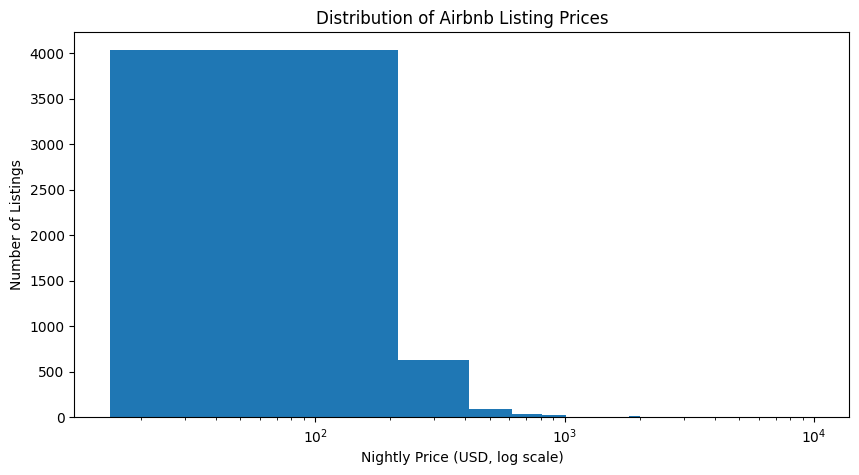

In [9]:
plt.figure(figsize=(10, 5))
plt.hist(clean['price'], bins=50)
plt.xscale('log')
plt.xlabel('Nightly Price (USD, log scale)')
plt.ylabel('Number of Listings')
plt.title('Distribution of Airbnb Listing Prices')
plt.show()

**Interpretation:** Most listings are concentrated at relatively low-to-moderate nightly prices, while a smaller number of expensive listings create a long right tail. The log scale makes the central distribution easier to inspect without deleting high-price observations.


### Room type distribution


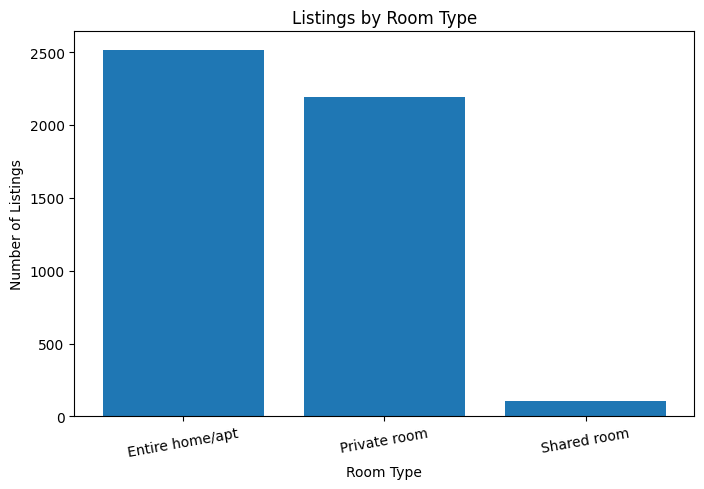

In [10]:
plt.figure(figsize=(8, 5))
counts = clean['room_type'].value_counts()
plt.bar(counts.index, counts.values)
plt.xlabel('Room Type')
plt.ylabel('Number of Listings')
plt.title('Listings by Room Type')
plt.xticks(rotation=10)
plt.show()

**Interpretation:** Entire homes/apartments and private rooms make up the overwhelming majority of listings. Shared rooms represent a much smaller part of the dataset.


### Neighbourhood group distribution


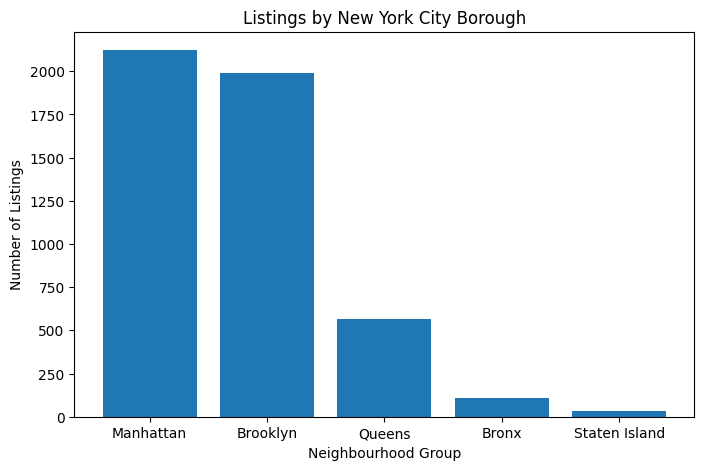

In [11]:
plt.figure(figsize=(8, 5))
counts = clean['neighbourhood_group'].value_counts()
plt.bar(counts.index, counts.values)
plt.xlabel('Neighbourhood Group')
plt.ylabel('Number of Listings')
plt.title('Listings by New York City Borough')
plt.show()

**Interpretation:** Manhattan and Brooklyn contain most of the listings in the provided sample. The Bronx, Queens, and Staten Island contribute fewer listings, so their summary statistics should be interpreted with their smaller sample sizes in mind.


### Engineered price-category distribution


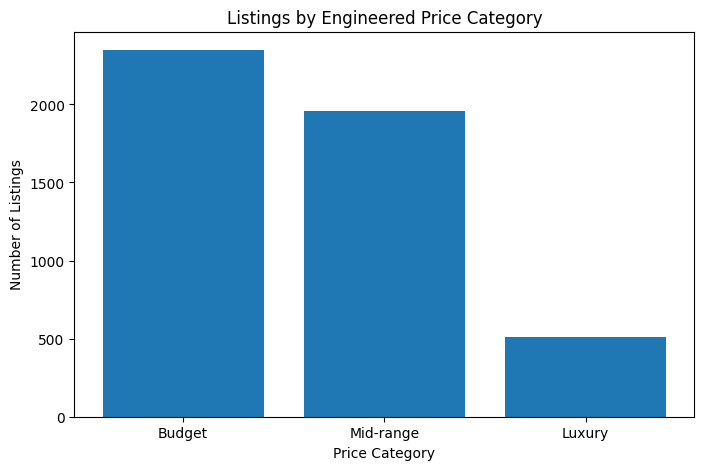

In [12]:
plt.figure(figsize=(8, 5))
counts = clean['price_category'].value_counts().reindex(['Budget', 'Mid-range', 'Luxury'])
plt.bar(counts.index.astype(str), counts.values)
plt.xlabel('Price Category')
plt.ylabel('Number of Listings')
plt.title('Listings by Engineered Price Category')
plt.show()

**Interpretation:** The engineered categories provide a simple view of the market segments. Budget listings form a substantial share, while the luxury group is smaller and represents the upper end of the observed price distribution.


## 4. Bivariate & Multivariate Analysis

### Price by neighbourhood group

Because price is skewed, medians are especially useful for comparing typical listing prices across boroughs.


In [13]:
borough_price = clean.groupby('neighbourhood_group')['price'].agg(['count', 'median', 'mean']).sort_values('median', ascending=False)
borough_price

,count,median,mean
neighbourhood_group,,,
Manhattan,2123,150.0,204.765426
Brooklyn,1989,90.0,121.820513
Staten Island,36,85.0,113.944444
Queens,564,75.0,100.226950
Bronx,108,65.0,82.611111


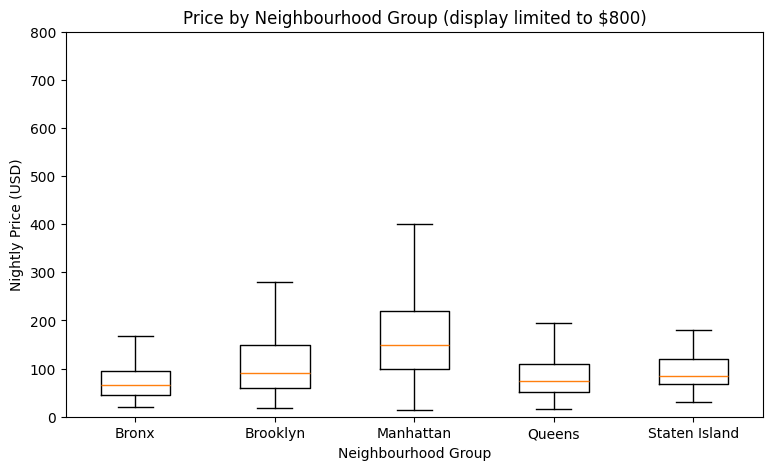

In [14]:
plt.figure(figsize=(9, 5))
groups = [g['price'].values for _, g in clean.groupby('neighbourhood_group')]
labels = list(clean.groupby('neighbourhood_group').groups.keys())
plt.boxplot(groups, tick_labels=labels, showfliers=False)
plt.ylim(0, 800)
plt.xlabel('Neighbourhood Group')
plt.ylabel('Nightly Price (USD)')
plt.title('Price by Neighbourhood Group (display limited to $800)')
plt.show()

**Interpretation:** Manhattan has the highest median listing price in the cleaned sample, followed by Brooklyn. The boxplot also shows substantial within-borough price variation, so borough alone does not determine the price of a listing.


### Price by room type


In [15]:
room_price = clean.groupby('room_type')['price'].agg(['count', 'median', 'mean']).sort_values('median', ascending=False)
room_price

,count,median,mean
room_type,,,
Entire home/apt,2517,160.0,214.751291
Private room,2195,70.0,90.289749
Shared room,108,50.0,72.731481


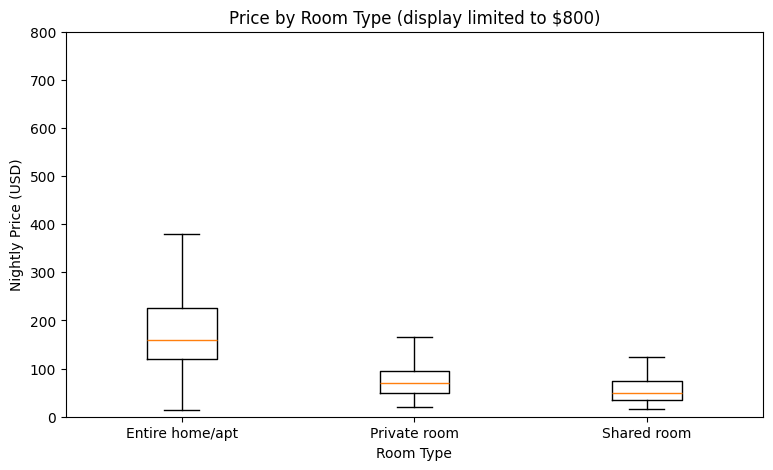

In [16]:
plt.figure(figsize=(9, 5))
groups = [g['price'].values for _, g in clean.groupby('room_type')]
labels = list(clean.groupby('room_type').groups.keys())
plt.boxplot(groups, tick_labels=labels, showfliers=False)
plt.ylim(0, 800)
plt.xlabel('Room Type')
plt.ylabel('Nightly Price (USD)')
plt.title('Price by Room Type (display limited to $800)')
plt.show()

**Interpretation:** Entire homes/apartments have a substantially higher typical price than private rooms and shared rooms. This indicates that room type is an important descriptive factor associated with listing price.


### Correlation heatmap

A correlation matrix is calculated for numeric variables. The heatmap helps identify linear relationships with price and relationships among the other numeric fields.


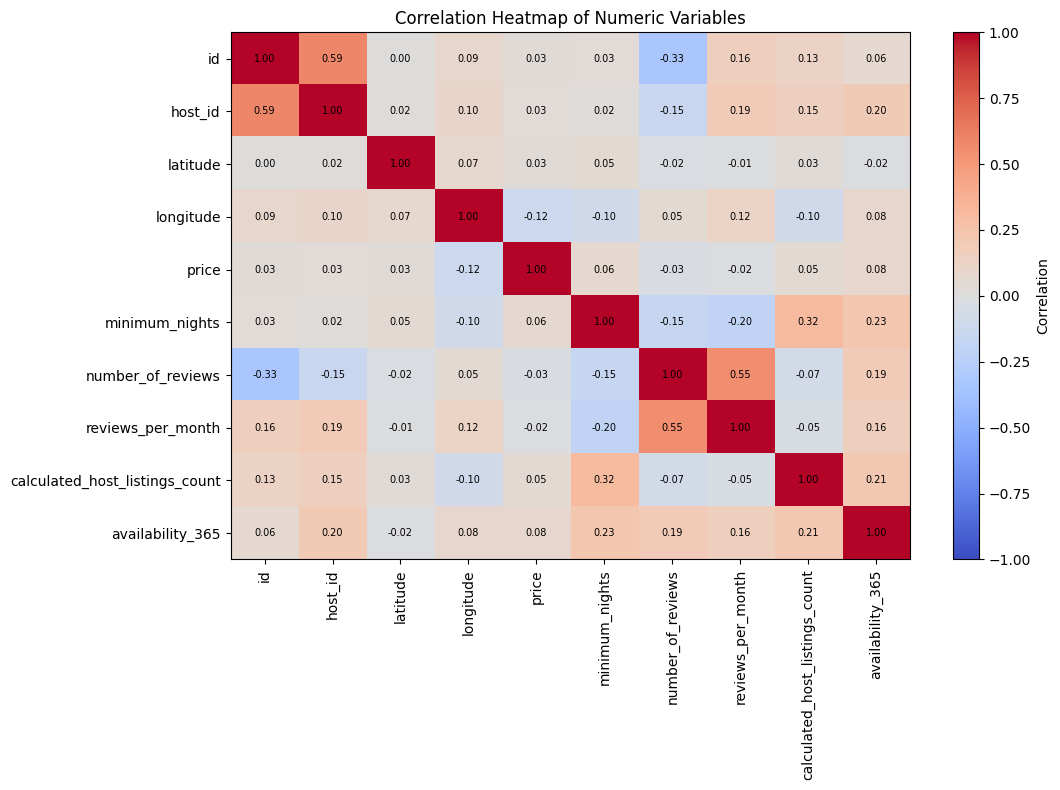

Correlations with price:
price                             1.000000
availability_365                  0.083718
minimum_nights                    0.064630
calculated_host_listings_count    0.049198
host_id                           0.031555
id                                0.030749
latitude                          0.030238
reviews_per_month                -0.023315
number_of_reviews                -0.034996
longitude                        -0.124725
Name: price, dtype: float64


In [17]:
numeric_for_corr = clean.select_dtypes(include=np.number)
corr = numeric_for_corr.corr()

plt.figure(figsize=(11, 8))
plt.imshow(corr, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.title('Correlation Heatmap of Numeric Variables')
plt.tight_layout()
plt.show()

print("Correlations with price:")
print(corr['price'].sort_values(ascending=False))

**Interpretation:** Among the numeric variables, `availability_365` has the strongest positive correlation with price in this cleaned dataset, at about 0.084. This is still a weak correlation, meaning that availability alone has little linear relationship with price. Price itself is so more strongly differentiated by categorical factors such as room type and borough than by most numeric variables.


### Three-variable relationship: room type within borough

The next analysis combines borough, room type, and price. Median price is used to reduce the influence of extreme values.


In [18]:
three_way = clean.groupby(['neighbourhood_group', 'room_type'])['price'].median().unstack()
three_way

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,99.0,50.0,38.0
Brooklyn,145.0,64.0,35.0
Manhattan,190.0,90.0,69.0
Queens,122.5,60.0,45.0
Staten Island,105.0,55.0,75.0


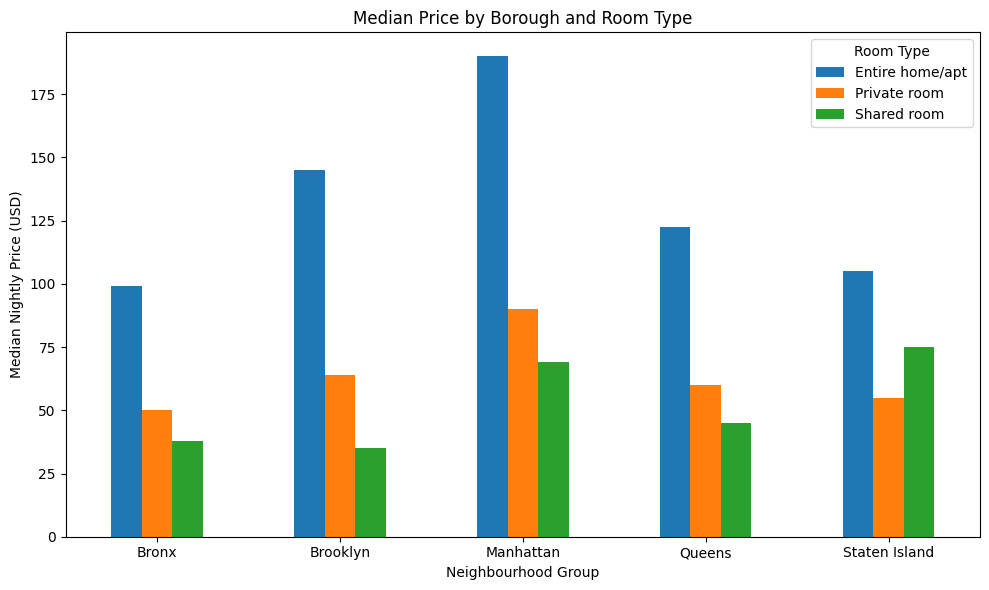

In [19]:
pivot = clean.pivot_table(index='neighbourhood_group', columns='room_type', values='price', aggfunc='median')
ax = pivot.plot(kind='bar', figsize=(10, 6))
ax.set_xlabel('Neighbourhood Group')
ax.set_ylabel('Median Nightly Price (USD)')
ax.set_title('Median Price by Borough and Room Type')
plt.xticks(rotation=0)
plt.legend(title='Room Type')
plt.tight_layout()
plt.show()

**Interpretation:** Entire homes/apartments generally have the highest median prices within each borough, while shared rooms are generally the lowest. Manhattan shows the highest typical prices across the major room-type groups, demonstrating that location and room type interact when describing price.


### Availability and price by room type

This additional multivariate view examines whether listings with different room types show different availability patterns and how their prices compare.


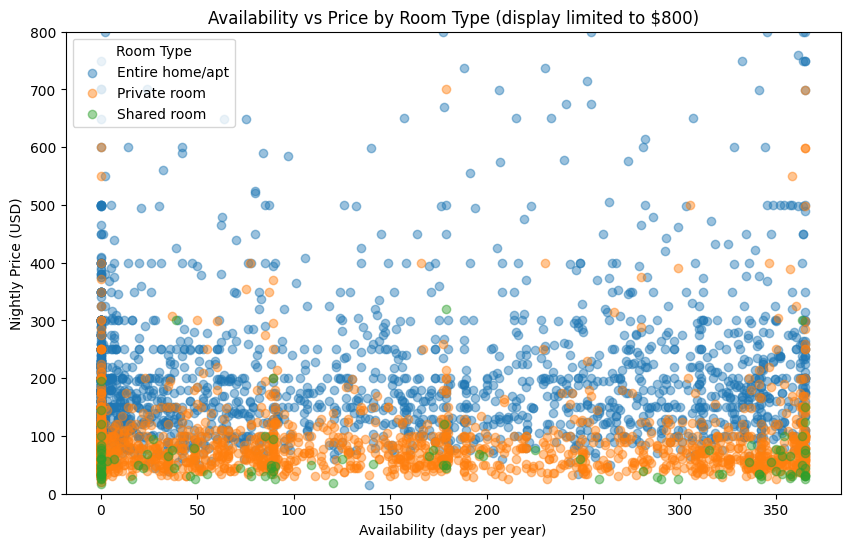

In [20]:
plt.figure(figsize=(10, 6))
for room, g in clean.groupby('room_type'):
    plt.scatter(g['availability_365'], g['price'], alpha=0.45, label=room)
plt.ylim(0, 800)
plt.xlabel('Availability (days per year)')
plt.ylabel('Nightly Price (USD)')
plt.title('Availability vs Price by Room Type (display limited to $800)')
plt.legend(title='Room Type')
plt.show()

**Interpretation:** The scatterplot shows broad overlap between availability and price, with no strong simple linear pattern. Room type creates visible separation in typical price levels, while availability varies substantially within each room type.


## 5. Key Insights & Actionable Recommendation

1. **Location matters:** Manhattan has the highest median listing price in the cleaned sample, while the Bronx has the lowest median.
2. **Room type matters strongly:** Entire homes/apartments have a much higher median price than private or shared rooms.
3. **Price is highly skewed:** A small number of high-priced listings create a long right tail, so medians and log-scale visualizations are useful.
4. **Numeric correlations with price are weak:** `availability_365` is the strongest positive numeric correlation with price, but the relationship is still weak.
5. **Borough and room type interact:** The typical price of a room type changes across boroughs, so hosts should consider both factors rather than using one citywide price.
6. **Actionable recommendation:** A new host should benchmark comparable listings using both **borough/neighbourhood and room type**, then position the nightly price within the observed local range instead of relying on a citywide average.


In [21]:
# Compact final metrics used to support the conclusions
print("Final cleaned dataset shape:", clean.shape)
print("\nMedian price by borough:")
print(clean.groupby('neighbourhood_group')['price'].median().sort_values(ascending=False))
print("\nMedian price by room type:")
print(clean.groupby('room_type')['price'].median().sort_values(ascending=False))
print("\nStrongest numeric correlation with price (excluding price itself):")
print(corr['price'].drop('price').abs().sort_values(ascending=False).head(1))

Final cleaned dataset shape: (4820, 17)

Median price by borough:
neighbourhood_group
Manhattan        150.0
Brooklyn          90.0
Staten Island     85.0
Queens            75.0
Bronx             65.0
Name: price, dtype: float64

Median price by room type:
room_type
Entire home/apt    160.0
Private room        70.0
Shared room         50.0
Name: price, dtype: float64

Strongest numeric correlation with price (excluding price itself):
longitude    0.124725
Name: price, dtype: float64


## Submission Checklist

- [x] CSV loaded with Pandas
- [x] First rows, shape, and `.info()` inspected
- [x] Numeric and categorical columns identified
- [x] Three initial observations documented
- [x] Missing values handled with different strategies and justified
- [x] Invalid price and unusually long minimum stays addressed
- [x] Date column converted to datetime
- [x] New `price_category` column engineered
- [x] At least four univariate visualizations
- [x] At least four bivariate/multivariate visualizations
- [x] Correlation heatmap included
- [x] Three-variable relationship analyzed
- [x] Interpretations provided for plots
- [x] Final 4–6 insights and an useful recommendation included
- [x] Notebook prepared for submission
